In [1]:
experiement_pth = '../visualisations/tmp/recon'
analysis_pth = '../visualisations/tmp/plot'

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.ticker import MultipleLocator
from IPython.display import Image, display

In [3]:

# load score.csv in each config folder
def load_score_csv(config, world_model):
    score_csv = os.path.join(experiement_pth, world_model, config, 'score.csv')
    if os.path.exists(score_csv):
        df = pd.read_csv(score_csv)
        return df
    else:
        print(f"File {score_csv} does not exist.")
        return None

rssm_configs = ['RGB2RGB-on-all-garment-800k', 'GC-RGB2RGB-on-all-garment-800k', 
                'GC-In-Only-RGB2RGB-on-all-garment-800k']
gc_rssm_configs = ['RGB2RGB-on-mix-200k-bonus-penalty-ca', 'RGB2RGB-on-mix-800k-all-garment-bonus-penalty']
    
# load all score.csv files
dfs = []
for config in rssm_configs:
    df = load_score_csv(config, 'rssm')
    if df is not None:
        dfs.append(df)
    # add a column for config name in each row
    df['config'] = config
# concatenate all dataframes
rssm_df = pd.concat(dfs, ignore_index=True)
rssm_df['wm'] = 'RSSM'
display(rssm_df)


# load gc score.csv files
gc_dfs = []
for config in gc_rssm_configs:
    df = load_score_csv(config, 'gc_rssm')
    if df is not None:
        gc_dfs.append(df)
    # add a column for config name in each row
    df['config'] = config
# concatenate all dataframes
gc_rssm_df = pd.concat(gc_dfs, ignore_index=True)
gc_rssm_df['wm'] = 'GC-RSSM'
display(gc_rssm_df)


,Posterior/Prior,Object Type,MSE,SSIM,LPIPS,FID,KID,config,wm
0,Posterior,longsleeve,0.0038,0.9339,0.1133,0.0110,0.1432,RGB2RGB-on-all-garment-800k,RSSM
1,Prior 1,longsleeve,0.0205,0.7164,0.1855,0.0144,0.1089,RGB2RGB-on-all-garment-800k,RSSM
2,Prior 2,longsleeve,0.0255,0.7104,0.2022,0.0174,0.1227,RGB2RGB-on-all-garment-800k,RSSM
3,Prior 3,longsleeve,0.0326,0.6537,0.2269,0.0212,0.1017,RGB2RGB-on-all-garment-800k,RSSM
4,Posterior,dress,0.0024,0.9536,0.0925,0.0162,0.1433,RGB2RGB-on-all-garment-800k,RSSM
5,Prior 1,dress,0.0186,0.7098,0.1820,0.0176,0.0938,RGB2RGB-on-all-garment-800k,RSSM
6,Prior 2,dress,0.0246,0.6540,0.1775,0.0193,0.1325,RGB2RGB-on-all-garment-800k,RSSM
7,Prior 3,dress,0.0255,0.6593,0.1949,0.0209,0.1201,RGB2RGB-on-all-garment-800k,RSSM
8,Posterior,skirt,0.0020,0.9506,0.0790,0.0159,0.0909,RGB2RGB-on-all-garment-800k,RSSM
9,Prior 1,skirt,0.0208,0.5157,0.1768,0.0161,0.0659,RGB2RGB-on-all-garment-800k,RSSM


,Posterior/Prior,Object Type,MSE,SSIM,LPIPS,FID,KID,config,wm
0,Posterior,longsleeve,0.0041,0.9212,0.1250,0.0096,0.1270,RGB2RGB-on-mix-200k-bonus-penalty-ca,GC-RSSM
1,Prior 1,longsleeve,0.0202,0.7191,0.1720,0.0120,0.0993,RGB2RGB-on-mix-200k-bonus-penalty-ca,GC-RSSM
2,Prior 2,longsleeve,0.0253,0.6362,0.1990,0.0143,0.0934,RGB2RGB-on-mix-200k-bonus-penalty-ca,GC-RSSM
3,Prior 3,longsleeve,0.0312,0.5813,0.2202,0.0168,0.0570,RGB2RGB-on-mix-200k-bonus-penalty-ca,GC-RSSM
4,Posterior,dress,0.0090,0.8160,0.1578,0.0127,0.1244,RGB2RGB-on-mix-200k-bonus-penalty-ca,GC-RSSM
5,Prior 1,dress,0.0283,0.5490,0.2513,0.0139,0.0964,RGB2RGB-on-mix-200k-bonus-penalty-ca,GC-RSSM
6,Prior 2,dress,0.0350,0.4950,0.2477,0.0152,0.1302,RGB2RGB-on-mix-200k-bonus-penalty-ca,GC-RSSM
7,Prior 3,dress,0.0297,0.5716,0.2502,0.0169,0.1183,RGB2RGB-on-mix-200k-bonus-penalty-ca,GC-RSSM
8,Posterior,skirt,0.0048,0.8547,0.1418,0.0141,0.1195,RGB2RGB-on-mix-200k-bonus-penalty-ca,GC-RSSM
9,Prior 1,skirt,0.0217,0.4102,0.2279,0.0146,0.1187,RGB2RGB-on-mix-200k-bonus-penalty-ca,GC-RSSM


Index(['Posterior/Prior', ' Object Type', ' MSE', ' SSIM', ' LPIPS', ' FID',
       ' KID', 'config', 'wm'],
      dtype='object')
Index(['Posterior/Prior', ' Object Type', ' MSE', ' SSIM', ' LPIPS', ' FID',
       ' KID', 'config', 'wm'],
      dtype='object')
Index(['Posterior/Prior', ' Object Type', ' MSE', ' SSIM', ' LPIPS', ' FID',
       ' KID', 'config', 'wm'],
      dtype='object')
Index(['Posterior/Prior', ' Object Type', ' MSE', ' SSIM', ' LPIPS', ' FID',
       ' KID', 'config', 'wm'],
      dtype='object')


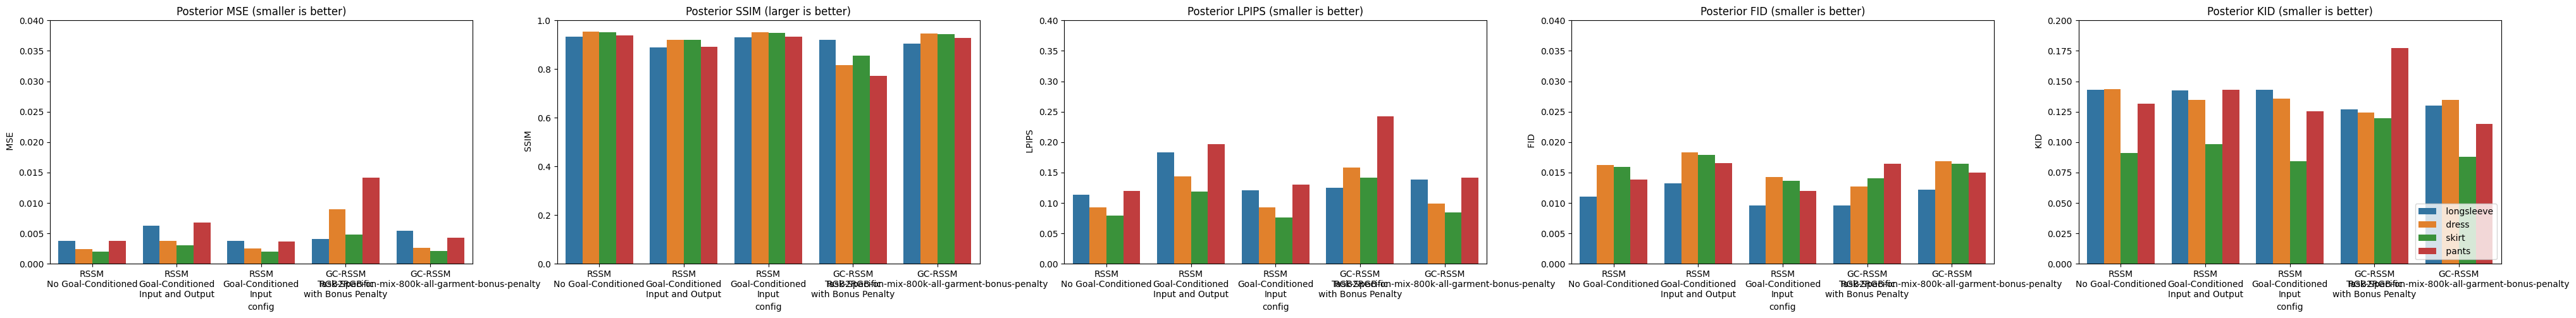

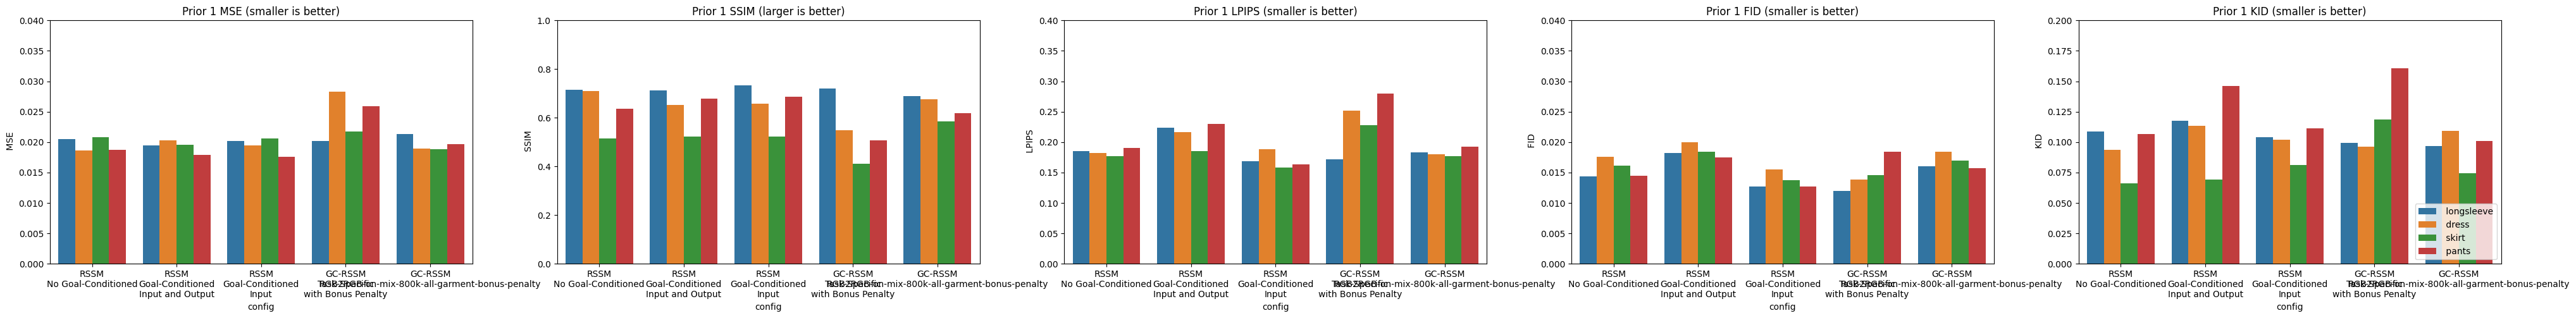

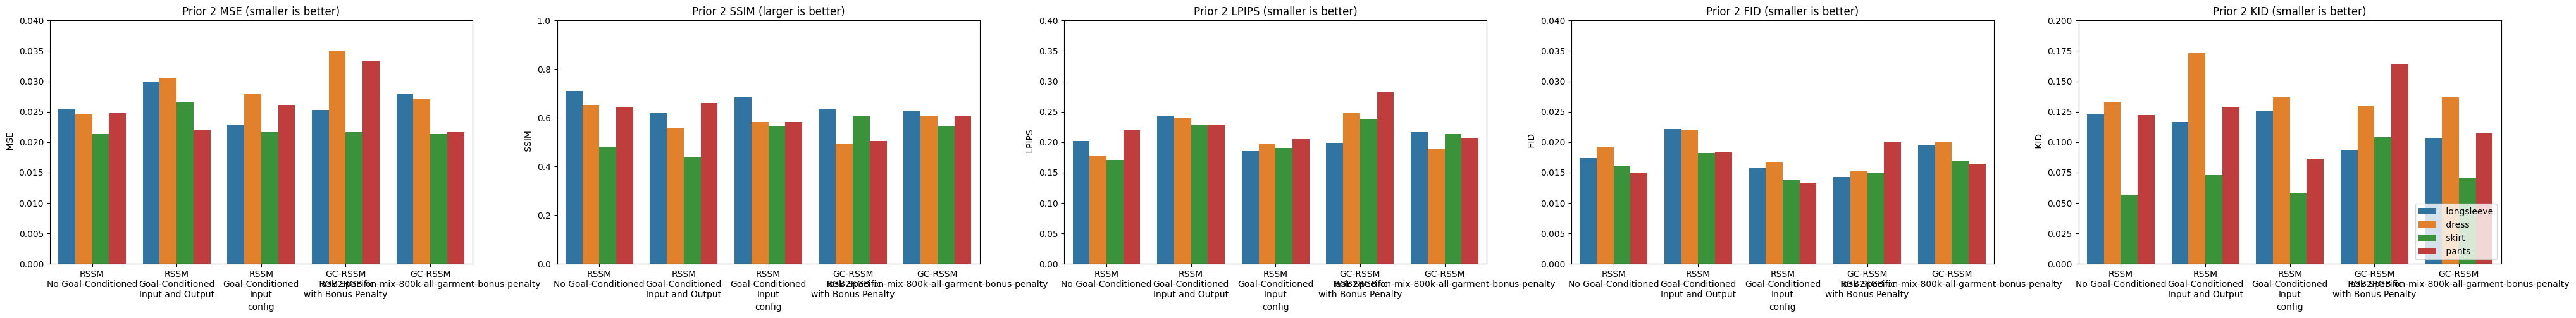

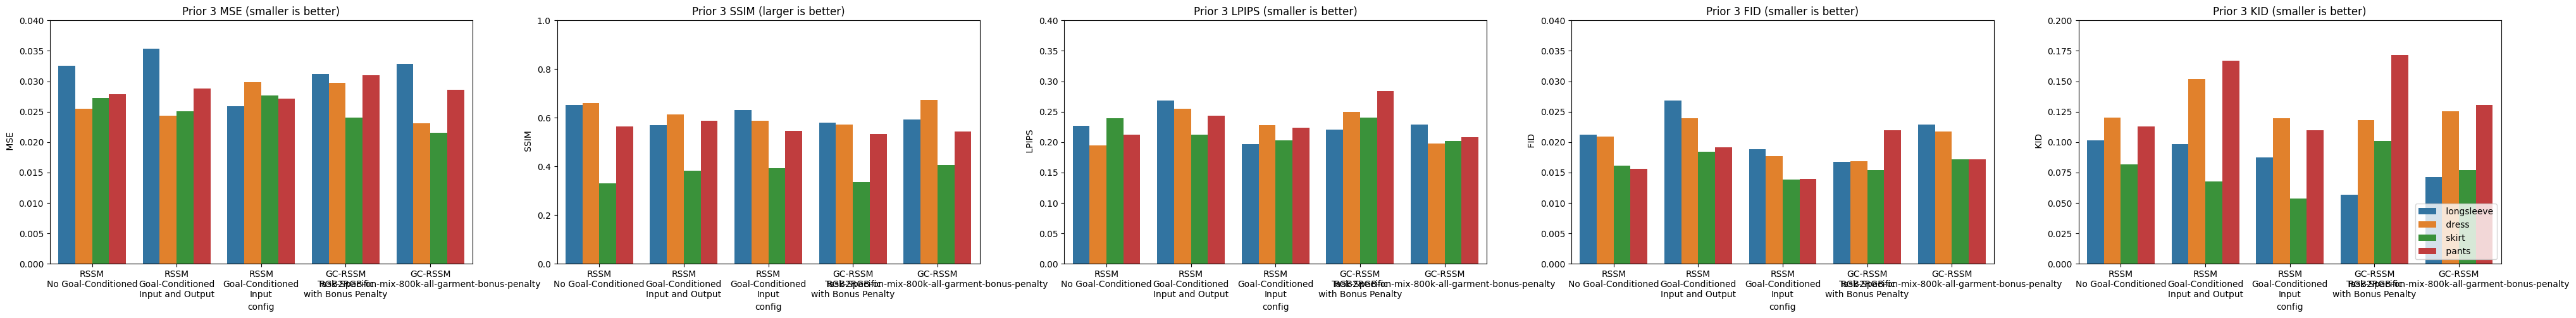

In [4]:
## make a plot for each metrics, where the x-axis is the config and y-axis is the metrics, hue is the object; use seaborn
plot_df_ = pd.concat([rssm_df, gc_rssm_df], ignore_index=True)

config2label = {
    'RGB2RGB-on-all-garment-800k': 'No Goal-Conditioned',
    'GC-In-Only-RGB2RGB-on-all-garment-800k': 'Goal-Conditioned\nInput',
    'GC-RGB2RGB-on-all-garment-800k': 'Goal-Conditioned\nInput and Output',
    'RGB2RGB-on-mix-200k-bonus-penalty-ca': 'Task-Specific\nwith Bonus Penalty',
}
for k, v in config2label.items():
    plot_df_['config'] = plot_df_['config'].replace(k, v)
## add world model name to the config
plot_df_['config'] = plot_df_['wm'] + '\n' + plot_df_['config']

def plot_recon_score(plot_df, target='Posterior'):
## only posterior
    plot_df = plot_df[plot_df['Posterior/Prior'] == target]
    # display(plot_df)
    # print all header names
    print(plot_df.columns)


    # put the above graphs in one line
    fig, axs = plt.subplots(1, 5, figsize=(50, 5))
    sns.barplot(data=plot_df, x='config', y=' MSE', hue=' Object Type', ax=axs[0])
    axs[0].set_title(f'{target} MSE (smaller is better)')
    ## set y-axis to be 0-1
    axs[0].set_ylim(0, 0.04)
    axs[0].legend_.remove()

    sns.barplot(data=plot_df, x='config', y=' SSIM', hue=' Object Type', ax=axs[1])
    axs[1].set_title(f'{target} SSIM (larger is better)')
    axs[1].set_ylim(0, 1)
    axs[1].legend_.remove()
    sns.barplot(data=plot_df, x='config', y=' LPIPS', hue=' Object Type', ax=axs[2])
    axs[2].set_title(f'{target} LPIPS (smaller is better)')
    axs[2].set_ylim(0, 0.4)
    axs[2].legend_.remove()
    sns.barplot(data=plot_df, x='config', y=' FID', hue=' Object Type', ax=axs[3])
    axs[3].set_title(f'{target} FID (smaller is better)')
    axs[3].set_ylim(0, 0.04)
    axs[3].legend_.remove()
    sns.barplot(data=plot_df, x='config', y=' KID', hue=' Object Type', ax=axs[4])
    axs[4].set_title(f'{target} KID (smaller is better)')
    axs[4].set_ylim(0, 0.2)
    axs[4].legend(loc='lower right')

# sns.barplot(data=plot_df, x='config', y='IoU', hue='object', ax=axs[2])
# axs[2].set_title('IoU')
# axs[2].legend_.remove()
# # axs[2].legend(loc='lower right')
# sns.barplot(data=plot_df, x='config', y='success_rate', hue='object', ax=axs[3])
# axs[3].set_title('Success Rate')
# axs[3].legend(loc='upper right')
# plt.savefig(os.path.join(analysis_pth, 'all_metrics.png'))


plot_recon_score(plot_df_, target='Posterior')
plot_recon_score(plot_df_, target='Prior 1')
plot_recon_score(plot_df_, target='Prior 2')
plot_recon_score(plot_df_, target='Prior 3')


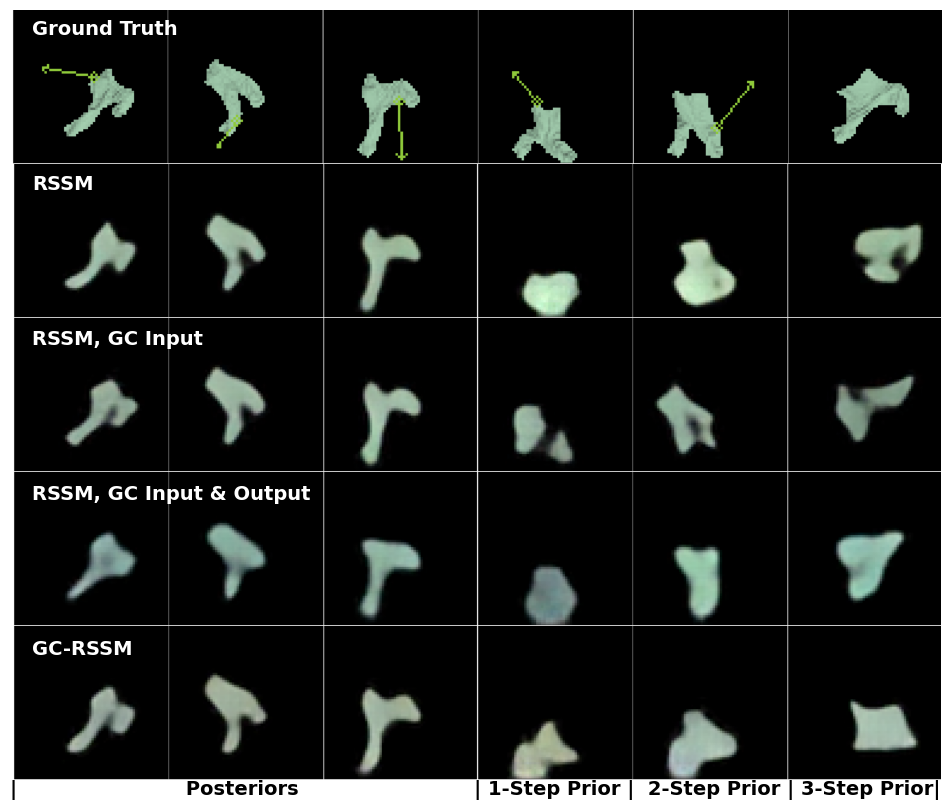

In [5]:
## visualise the recon

## top row is the ground truth
## each row represents a config

## the recon images are saved in recon/{world_model}/{config}/{object_type}/trial_{id}/{posterior/prior}.png
### Models trained on all garments

wm_and_configs = [
    ('rssm', 'RGB2RGB-on-all-garment-800k', 'RSSM'),
    ('rssm', 'GC-In-Only-RGB2RGB-on-all-garment-800k', 'RSSM, GC Input'),
    ('rssm', 'GC-RGB2RGB-on-all-garment-800k', 'RSSM, GC Input & Output'),
    ('gc_rssm', 'RGB2RGB-on-mix-800k-all-garment-bonus-penalty', 'GC-RSSM'),
]
obj = 'pants'
trial = 0
fig, axs = plt.subplots(len(wm_and_configs) + 1, 1, figsize=(20, 10))


recon_paths = []
labels = []
for wm, config, label in wm_and_configs:
    recon_pth = os.path.join(experiement_pth, wm, config, obj, f'trial_{trial}')
    if not os.path.exists(recon_pth):
        print(f"Recon path {recon_pth} does not exist.")
        continue
    recon_paths.append(recon_pth)
    labels.append(label)

crop_margin = 12
# plot the ground truth to the first row
gt_pth = os.path.join(recon_paths[-1], 'ground_truth.png')

gt_img = plt.imread(gt_pth)[crop_margin:-crop_margin, crop_margin:-crop_margin]
axs[0].imshow(gt_img)
axs[0].axis('off')
## draw a white bold text on the top left corner of the image
fig.text(0.29, 0.87, 'Ground Truth', ha='left', va='top',
         fontsize=14, fontweight='bold', color='white')
# axs[0].set_title('Ground Truth')



# plot the recon images
for i, recon_pth in enumerate(recon_paths):
    recon_img_posterior = os.path.join(recon_pth, 'posterior.png')
    recon_img_prior = os.path.join(recon_pth, 'prior.png')

    
    
    posterior_image = plt.imread(recon_img_posterior)[crop_margin:-crop_margin, crop_margin:-crop_margin]
    prior_image = plt.imread(recon_img_prior)[crop_margin:-crop_margin, crop_margin:-crop_margin]
    recon_img = np.concatenate((posterior_image, prior_image), axis=1)

    ## draw a white bold text on the top left corner of the image
    fig.text(0.29, 0.87 - (i + 1) * 0.155, labels[i], ha='left', va='top',
             fontsize=14, fontweight='bold', color='white')

    axs[i + 1].imshow(recon_img)
    axs[i + 1].axis('off')

# add ! Posterior | Piror 1 | Prior 2 | Prior 3 to the bottom of the figure
fig.text(0.279, 0.1, '|                         Posteriors                          | 1-Step Prior |  2-Step Prior | 3-Step Prior|', 
         ha='left', va='center', fontsize=14, fontweight='bold')
# Remove vertical spacing between rows
fig.subplots_adjust(hspace=0)

# Remove margins around the figure (optional)
plt.margins(0)
    # axs[i + 1].set_title(f'{wm_and_configs[i][0]} - {wm_and_configs[i][1]} - Prior')

plt.savefig(os.path.join(analysis_pth, 'recon-all-garments.png'), bbox_inches='tight', dpi=300)

   

In [6]:

# Create latex tables for each target, there are 4 big columns for Posterior, Prior 1, Prior 2, Prior 3
# under each big column, there are 5 small columns for MSE, SSIM, LPIPS, FID, KID
# each row is a config
plot_df_ = pd.concat([rssm_df, gc_rssm_df], ignore_index=True)
wm_and_configs = [
    ('RSSM', 'RGB2RGB-on-all-garment-800k', 'RSSM'),
    ('RSSM', 'GC-In-Only-RGB2RGB-on-all-garment-800k', 'RSSM, GC Input'),
    ('RSSM', 'GC-RGB2RGB-on-all-garment-800k', 'RSSM, GC Input \& Output'),
    ('GC-RSSM', 'RGB2RGB-on-mix-800k-all-garment-bonus-penalty', 'GC-RSSM'),
]

#display(plot_df_)
print('\\begin{table*}[t!]')
print('\centering')
print('\\caption{Reconstruction metrics for different world models and configurations.}')
print('\\label{tab:recon_metrics}')
print('\\resizebox{\\textwidth}{!}{')
print('\\begin{tabular}{l|ccccc|ccccc|ccccc|ccccc}')
print('\\toprule')
print('Model & \\multicolumn{5}{c|}{Posterior} & \\multicolumn{5}{c|}{Prior 1} & \\multicolumn{5}{c|}{Prior 2} & \\multicolumn{5}{c}{Prior 3} \\\\')
print('\\midrule')

## print the metrics name
for _ in range(4):
    print(' & MSE & SSIM & LPIPS & FID & KID ', end=' ')
print('\\\\')

for wm, configs, label in wm_and_configs:
    # filter the dataframe for the current world model and config
    df = plot_df_[plot_df_['wm'] == wm]
    #display(df)
    df = df[df['config'] == configs]
    #display(df)
    #print('config:', configs)
    
    # print the row for each config
    row = f"{label} & "
    for target in ['Posterior', 'Prior 1', 'Prior 2', 'Prior 3']:
        target_df = df[df['Posterior/Prior'] == target]
        #display(target_df)
        # get the average of each metric
        if target_df.empty:
            row += 'N/A & N/A & N/A & N/A & N/A & '
        else:
            # append the metrics to the row
            row += f"{target_df[' MSE'].mean()*100:.2f} & {target_df[' SSIM'].mean()*100:.2f} & {target_df[' LPIPS'].mean()*100:.2f} & {target_df[' FID'].mean()*100:.2f} & {target_df[' KID'].mean()*100:.2f} & "

        #row += f"{target_df[' MSE'].values[0]:.4f} & {target_df[' SSIM'].values[0]:.4f} & {target_df[' LPIPS'].values[0]:.4f} & {target_df[' FID'].values[0]:.4f} & {target_df[' KID'].values[0]:.4f} & "
    
    # remove the last '&' and add '\\'
    row = row[:-2] + '\\\\'
    print(row)
print('\\bottomrule')
print('\\end{tabular}')

print('}')
print('\\end{table*}')



\begin{table*}[t!]
\centering
\caption{Reconstruction metrics for different world models and configurations.}
\label{tab:recon_metrics}
\resizebox{\textwidth}{!}{
\begin{tabular}{l|ccccc|ccccc|ccccc|ccccc}
\toprule
Model & \multicolumn{5}{c|}{Posterior} & \multicolumn{5}{c|}{Prior 1} & \multicolumn{5}{c|}{Prior 2} & \multicolumn{5}{c}{Prior 3} \\
\midrule
 & MSE & SSIM & LPIPS & FID & KID   & MSE & SSIM & LPIPS & FID & KID   & MSE & SSIM & LPIPS & FID & KID   & MSE & SSIM & LPIPS & FID & KID  \\
RSSM & 0.30 & 94.41 & 10.13 & 1.42 & 12.72 & 1.97 & 64.48 & 18.37 & 1.57 & 9.38 & 2.40 & 62.24 & 19.25 & 1.69 & 10.85 & 2.83 & 55.24 & 21.83 & 1.85 & 10.41 \\
RSSM, GC Input & 0.30 & 94.12 & 10.50 & 1.24 & 12.21 & 1.95 & 65.02 & 16.97 & 1.36 & 9.98 & 2.46 & 60.40 & 19.45 & 1.49 & 10.17 & 2.77 & 53.97 & 21.28 & 1.61 & 9.25 \\
RSSM, GC Input \& Output & 0.50 & 90.52 & 16.05 & 1.65 & 12.97 & 1.93 & 64.11 & 21.38 & 1.85 & 11.17 & 2.73 & 56.98 & 23.55 & 2.02 & 12.28 & 2.84 & 53.90 & 24.46 & 2.21 & 1